In [1]:

!pip install -q pandas numpy matplotlib scikit-learn tensorflow


In [6]:
import pandas as pd
import numpy as np

# 1. Load the extracted dataset (first 10,000 records as requested)
file_path = '/content/extracted_data/synthetic_traffic_benchmark_200k.csv'
df = pd.read_csv(file_path, nrows=10000)

# Strip whitespaces from column names
df.columns = df.columns.str.strip()
print("Dataset loaded successfully. Shape:", df.shape)
print("Columns:", df.columns.tolist())

# Display missing values before cleaning
print("\nMissing values count before cleaning:")
print(df.isnull().sum())

# Display sample records
display(df.head())

Dataset loaded successfully. Shape: (10000, 29)
Columns: ['Record_ID', 'Timestamp', 'Date', 'Hour', 'Month', 'Day_of_Week', 'Time_of_Day', 'Is_Holiday', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Speed_Limit_kmh', 'Weather', 'Road_Condition', 'Visibility_m', 'Congestion_Index', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Baseline_Expected_Response_Time_min', 'Accident_Occurred', 'Collision_Type', 'Vehicles_Involved', 'Accident_Severity', 'Dispatch_Priority', 'Actual_Response_Time_min', 'Road_Closure_Duration_min']

Missing values count before cleaning:
Record_ID                                 0
Timestamp                                 0
Date                                      0
Hour                                      0
Month                                     0
Day_of_Week                               0
Time_of_Day                               0
Is_Holiday                                0
Area_Type                      

,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0000000,2024-03-14 17:35:06.841829282,2024-03-14,17,3,Thursday,Evening Peak,0,Urban,Interstate,...,7.2,49.0,6.2,0,NaN,0,No Accident,NaN,0.0,0.0
1,REC_0000001,2023-05-25 08:10:56.398060108,2023-05-25,8,5,Thursday,Morning Peak,0,Suburban,Interstate,...,9.4,70.1,15.0,0,NaN,0,No Accident,NaN,0.0,0.0
2,REC_0000002,2023-11-07 08:25:17.721608262,2023-11-07,8,11,Tuesday,Morning Peak,0,Suburban,Interstate,...,2.9,71.9,14.6,0,NaN,0,No Accident,NaN,0.0,0.0
3,REC_0000003,2024-07-24 09:30:00.947374674,2024-07-24,9,7,Wednesday,Morning Peak,0,Suburban,Collector,...,4.4,58.7,13.2,0,NaN,0,No Accident,NaN,0.0,0.0
4,REC_0000004,2024-04-03 09:34:07.316651267,2024-04-03,9,4,Wednesday,Morning Peak,0,Urban,Local,...,1.8,25.4,7.8,0,NaN,0,No Accident,NaN,0.0,0.0


In [8]:
# 2. Detect key columns manually
time_col = 'Timestamp'
target_col = 'Congestion_Index'

print(f"Detected Time Column: {time_col}")
print(f"Detected Target (Congestion) Column: {target_col}")

# 3. Handle missing values and types
if time_col:
    df[time_col] = pd.to_datetime(df[time_col], errors='coerce')
    df = df.dropna(subset=[time_col]).copy()

# Fill numerical columns with median, categorical columns with 'Unknown'
for col in df.columns:
    if col == time_col:
        continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna('Unknown')

print("\nData cleaning and column detection completed. Remaining missing values:", df.isnull().sum().sum())

Detected Time Column: Timestamp
Detected Target (Congestion) Column: Congestion_Index

Data cleaning and column detection completed. Remaining missing values: 0


In [9]:
from sklearn.preprocessing import LabelEncoder

# 4. Convert Categorical data into numbers
encoders = {}
for col in df.select_dtypes(include=['object', 'category']).columns:
    if col == time_col:
        continue
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col].astype(str))
    encoders[col] = encoder

print("Categorical columns converted to numeric keys.")
display(df.head())

Categorical columns converted to numeric keys.


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,0,2024-03-14 17:35:06.841829282,800,17,3,4,0,0,2,2,...,7.2,49.0,6.2,0,4,0,3,3,0.0,0.0
1,1,2023-05-25 08:10:56.398060108,507,8,5,4,2,0,1,2,...,9.4,70.1,15.0,0,4,0,3,3,0.0,0.0
2,2,2023-11-07 08:25:17.721608262,672,8,11,5,2,0,1,2,...,2.9,71.9,14.6,0,4,0,3,3,0.0,0.0
3,3,2024-07-24 09:30:00.947374674,931,9,7,6,2,0,1,1,...,4.4,58.7,13.2,0,4,0,3,3,0.0,0.0
4,4,2024-04-03 09:34:07.316651267,819,9,4,6,2,0,2,3,...,1.8,25.4,7.8,0,4,0,3,3,0.0,0.0


In [10]:
# 5. Sort chronologically and group by hour
df = df.sort_values(time_col).reset_index(drop=True)
df['hour_time'] = df[time_col].dt.floor('h')

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
hourly = df.groupby('hour_time')[numeric_cols].mean().sort_index()

hourly['hour_of_day'] = hourly.index.hour
hourly['day_of_week'] = hourly.index.dayofweek

print("Hourly dataset shape:", hourly.shape)
display(hourly.head())

Hourly dataset shape: (8225, 30)


,Record_ID,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,Intersection_Type,...,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min,hour_of_day,day_of_week
hour_time,,,,,,,,,,,,,,,,,,,,,
2022-01-01 14:00:00,3324.0,0.0,14.0,1.0,2.0,1.0,0.0,1.0,3.0,2.0,...,9.1,0.0,4.0,0.0,3.0,3.0,0.0,0.0,14,5
2022-01-01 15:00:00,6753.0,0.0,15.0,1.0,2.0,1.0,0.0,1.0,0.0,0.0,...,7.9,0.0,4.0,0.0,3.0,3.0,0.0,0.0,15,5
2022-01-01 17:00:00,9613.0,0.0,17.0,1.0,2.0,0.0,0.0,1.0,0.0,0.0,...,8.7,0.0,4.0,0.0,3.0,3.0,0.0,0.0,17,5
2022-01-01 19:00:00,5453.0,0.0,19.0,1.0,2.0,0.0,0.0,0.0,1.0,0.0,...,22.4,0.0,4.0,0.0,3.0,3.0,0.0,0.0,19,5
2022-01-01 22:00:00,7123.0,0.0,22.0,1.0,2.0,3.0,0.0,2.0,3.0,2.0,...,7.9,0.0,4.0,0.0,3.0,3.0,0.0,0.0,22,5


In [11]:
from sklearn.preprocessing import MinMaxScaler

# 6. Normalize numerical features
# Remove invariant columns
constant_cols = [c for c in hourly.columns if hourly[c].nunique() <= 1 and c != target_col]
hourly = hourly.drop(columns=constant_cols)

data = hourly.astype('float32').values
target_index = hourly.columns.get_loc(target_col)

n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

scaler = MinMaxScaler()
scaler.fit(data[:train_end])
scaled_data = scaler.transform(data)

# 7. Create sequential features
sequence_length = 24
X, y, positions = [], [], []
for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i, target_index])
    positions.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
positions = np.array(positions)

train_mask = positions < train_end
val_mask = (positions >= train_end) & (positions < val_end)
test_mask = positions >= val_end

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Sequences created successfully.")
print(f"Train size: {X_train.shape}, Val size: {X_val.shape}, Test size: {X_test.shape}")

Sequences created successfully.
Train size: (5733, 24, 30), Val size: (1234, 24, 30), Test size: (1234, 24, 30)


In [12]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# 8. Train the LSTM model
model = Sequential([
    LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0891 - val_loss: 0.0808
Epoch 2/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0832 - val_loss: 0.0792
Epoch 3/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0819 - val_loss: 0.0786
Epoch 4/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0805 - val_loss: 0.0786
Epoch 5/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0799 - val_loss: 0.0786
Epoch 6/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0799 - val_loss: 0.0787
Epoch 7/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0792 - val_loss: 0.0784
Epoch 8/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0788 - val_loss: 0.0785
Epoch 9/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0784 - val_loss: 0.0788
Epoch 10/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0782 - val_loss: 0.0785
Epoch 11/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0782 - val_loss: 0.0788
Epoch 12/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss:

-----------------
MAE: 22.7544
RMSE: 26.9381
-----------------


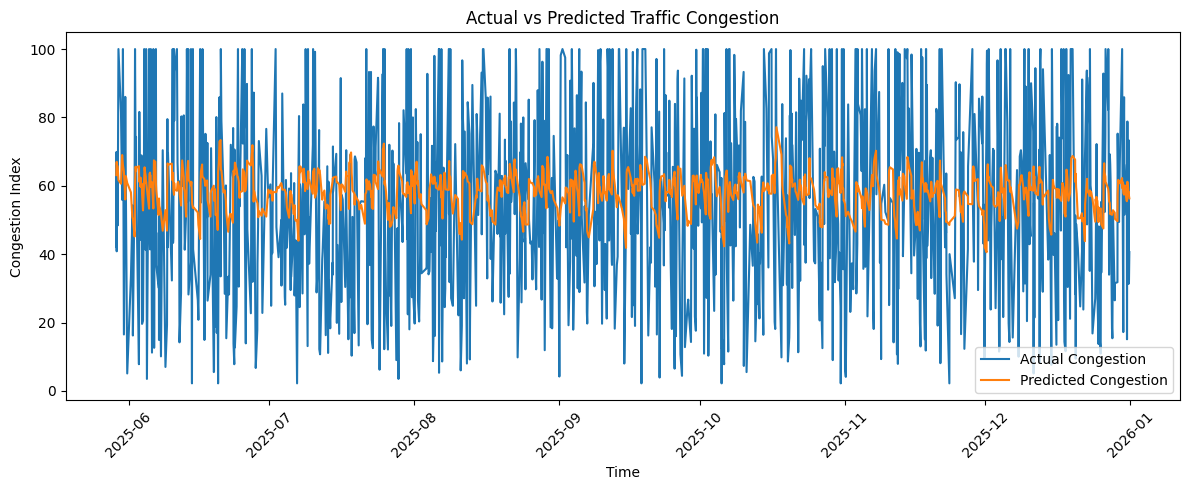

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# 9. Predictions and Metrics
predicted_scaled = model.predict(X_test, verbose=0).flatten()
target_min = scaler.data_min_[target_index]
target_range = scaler.data_range_[target_index]

actual = y_test * target_range + target_min
predicted = predicted_scaled * target_range + target_min

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("-----------------")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print("-----------------")

test_times = hourly.index[positions[test_mask]]

plt.figure(figsize=(12, 5))
plt.plot(test_times, actual, label='Actual Congestion')
plt.plot(test_times, predicted, label='Predicted Congestion')
plt.title('Actual vs Predicted Traffic Congestion')
plt.ylabel('Congestion Index')
plt.xlabel('Time')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()